# 02. Phân tích khám phá dữ liệu (Exploratory Data Analysis - EDA)

**Đề tài:** Nghiên cứu - trực quan hóa các đặc trưng âm thanh và dự đoán xu hướng bài hát thịnh hành trên Spotify.

Notebook thực hiện sáu nội dung phân tích khám phá thực chứng theo tiến trình nghiên cứu:
1. **Phân phối năm đặc trưng âm thanh chính:** Khảo sát hình thái phân phối của loudness, energy, speechiness, valence và duration trên toàn bộ 39,190 ca khúc trong dữ liệu bảng xếp hạng.
2. **Tương quan giữa các đặc trưng âm học:** Đánh giá mức độ liên hệ đơn điệu Spearman của 10 biến liên tục và nhận diện các cặp biến có thông tin chồng lấn.
3. **Xu hướng âm thanh Global và tính mùa vụ:** Quan sát sự dịch chuyển dài hạn của các đặc trưng âm thanh và chu kỳ lễ hội tháng 12 giai đoạn 2017–2022.
4. **Hạnh phúc quốc gia và cảm xúc âm nhạc:** Khảo sát tương quan giữa điểm hạnh phúc World Happiness Report và valence trên bảng xếp hạng các quốc gia.
5. **Diễn biến dịch COVID-19 và hồ sơ âm thanh:** Đối chiếu số ca tử vong tuần với các chỉ số âm thanh trong giai đoạn cùng quan sát 2020–2022.
6. **Phân phối nhãn dự báo mô hình:** Khảo sát quy mô và tỷ lệ nhãn dương đạt Global Top 50 trong 8 tuần trên tập huấn luyện Train.


### Khởi tạo môi trường phân tích
Đoạn mã nạp các thư viện tính toán số học, xử lý bảng dữ liệu và cấu hình thông số hiển thị đồ thị theo chuẩn thống nhất.


In [1]:
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

# Cấu hình giao diện biểu đồ
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
sns.set_theme(style='whitegrid')


### Nạp các bảng dữ liệu đã qua tiền xử lý
Đoạn mã nạp dữ liệu danh mục bài hát, các bảng Data Mart và bảng sự kiện bảng xếp hạng từ thư mục dữ liệu sạch.


In [2]:
root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
data_dir = root / 'data' / 'processed'

# Nạp các bảng dữ liệu sạch cốt lõi
df_tracks = pd.read_csv(data_dir / 'tracks_dimension.csv')
df_mart_audio = pd.read_parquet(data_dir / 'mart_audio_trend_weekly.parquet')
df_mart_whs = pd.read_parquet(data_dir / 'mart_country_year.parquet')
df_covid = pd.read_csv(data_dir / 'covid_weekly_clean.csv')

# Nạp các cột cần thiết từ bảng xếp hạng sạch
cols_chart = ['track_id', 'chart_country', 'week', 'rank', 'streams', 'duration']
df_charts = pd.read_parquet(data_dir / 'charts_clean.parquet', columns=cols_chart)

print('thông tin kích thước dữ liệu nạp:')
print(f'  tracks_dimension: {len(df_tracks):,} bài hát')
print(f'  mart_audio_trend_weekly: {len(df_mart_audio):,} dòng')
print(f'  mart_country_year: {len(df_mart_whs):,} dòng')
print(f'  charts_clean: {len(df_charts):,} dòng')


thông tin kích thước dữ liệu nạp:
  tracks_dimension: 39,190 bài hát
  mart_audio_trend_weekly: 5,548 dòng
  mart_country_year: 141 dòng
  charts_clean: 1,787,531 dòng


### Chuẩn bị dữ liệu phân phối năm đặc trưng
Đoạn mã chuyển đổi thời lượng bài hát sang đơn vị phút và tính toán các chỉ số thống kê trung tâm cùng phân vị cho năm đặc trưng.


In [3]:
df_feat = df_tracks.copy()
# Đổi thời lượng từ mili-giây sang phút
df_feat['duration_min'] = df_feat['duration'] / 60000.0

feat_cols = ['loudness', 'energy', 'speechiness', 'valence', 'duration_min']
stats_rows = []
for c in feat_cols:
    s = df_feat[c]
    stats_rows.append({'biến': c, 'mean': s.mean(), 'median': s.median(), 'q1': s.quantile(0.25), 'q3': s.quantile(0.75)})
df_feat_stats = pd.DataFrame(stats_rows).round(3)

print('thống kê vị trí và phân vị của năm đặc trưng:')
for _, r in df_feat_stats.iterrows():
    print(f"  {r['biến']}: mean = {r['mean']:.3f}, med = {r['median']:.3f}, q1 = {r['q1']:.3f}, q3 = {r['q3']:.3f}")


thống kê vị trí và phân vị của năm đặc trưng:
  loudness: mean = -7.026, med = -6.662, q1 = -8.391, q3 = -5.227
  energy: mean = 0.633, med = 0.645, q1 = 0.526, q3 = 0.754
  speechiness: mean = 0.131, med = 0.076, q1 = 0.043, q3 = 0.187
  valence: mean = 0.520, med = 0.520, q1 = 0.348, q3 = 0.691
  duration_min: mean = 3.341, med = 3.225, q1 = 2.791, q3 = 3.742


### Trực quan hóa hình thái phân phối năm đặc trưng
Đoạn mã vẽ năm biểu đồ phân phối dạng histogram kèm đường mật độ KDE, đánh dấu đường trung bình và trung vị của từng biến.


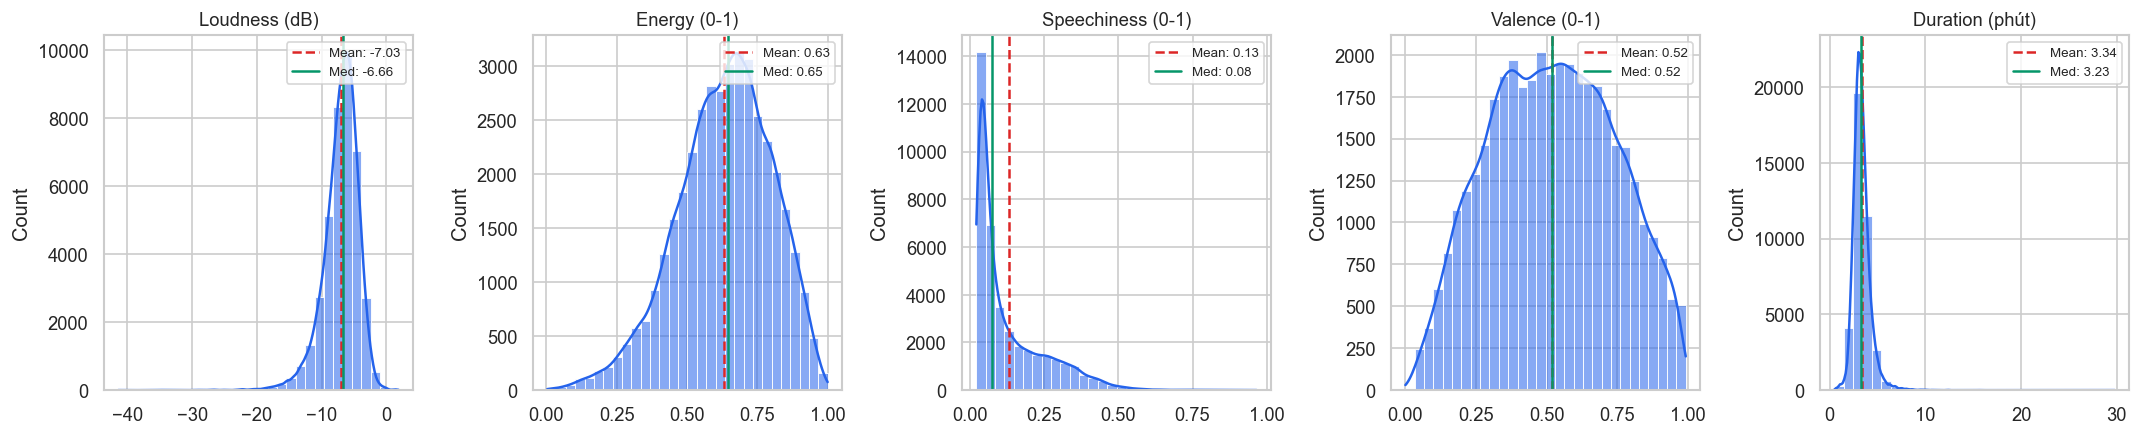

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.8))
feat_names = ['Loudness (dB)', 'Energy (0-1)', 'Speechiness (0-1)', 'Valence (0-1)', 'Duration (phút)']
for idx, (c, name) in enumerate(zip(feat_cols, feat_names)):
    ax = axes[idx]
    sns.histplot(df_feat[c], kde=True, ax=ax, color='#2563EB', bins=30, alpha=0.55)
    m_val = df_feat[c].mean()
    med_val = df_feat[c].median()
    ax.axvline(m_val, color='#DC2626', linestyle='--', linewidth=1.5, label=f'Mean: {m_val:.2f}')
    ax.axvline(med_val, color='#059669', linestyle='-', linewidth=1.5, label=f'Med: {med_val:.2f}')
    ax.set_title(name, fontsize=11)
    ax.set_xlabel('')
    ax.legend(fontsize=8, loc='upper right')
plt.tight_layout()
plt.show()


### Thống kê các ca khúc ngoại lệ ở dải đuôi phân phối
Đoạn mã đếm số lượng ca khúc nằm ngoài vùng tập trung chính của thời lượng và tỷ lệ lời nói để phục vụ nhận xét thống kê.


In [5]:
# Đếm số ca khúc có thời lượng dài hoặc mức lời nói cao
n_long_dur = int((df_feat['duration_min'] > 6.0).sum())
n_high_speech = int((df_feat['speechiness'] > 0.4).sum())
total_tracks = len(df_feat)

print('số lượng ca khúc nằm ngoài vùng tập trung:')
print(f'  thời lượng trên 6 phút: {n_long_dur:,} bài ({n_long_dur / total_tracks:.2%})')
print(f'  speechiness trên 0.4: {n_high_speech:,} bài ({n_high_speech / total_tracks:.2%})')


số lượng ca khúc nằm ngoài vùng tập trung:
  thời lượng trên 6 phút: 535 bài (1.37%)
  speechiness trên 0.4: 1,545 bài (3.94%)


### Nhận xét thực chứng phân phối năm đặc trưng
1. Loudness và Energy lệch trái rõ rệt với trung vị cao hơn trung bình (Loudness median = -6.662 dB [mean = -7.026 dB, Q1 = -8.391 dB, Q3 = -5.227 dB]; Energy median = 0.645 [mean = 0.633, Q1 = 0.526, Q3 = 0.754]). Điều này phản ánh đặc tính của các ca khúc lọt bảng xếp hạng thương mại thường ưu tiên mức âm lượng nén lớn và tiết tấu sôi động.
2. Speechiness lệch phải cực mạnh với trung vị 0.076 (Q1 = 0.043, Q3 = 0.187); phần lớn bài hát có tính chất giai điệu hát thông thường và chỉ có 3.94% ca khúc (1,545 bài trên tổng số 39,190 bài) có speechiness vượt 0.40 (nhóm ca khúc có mật độ lời nói / thoại vocal dày đặc).
3. Valence phân phối khá cân đối quanh mức 0.520 (mean = 0.520, median = 0.520, Q1 = 0.348, Q3 = 0.691). Thời lượng bài hát tập trung chặt chẽ quanh 3.2 phút (trung bình 3.341 phút, trung vị 3.225 phút, Q1 = 2.791 phút, Q3 = 3.742 phút); ca khúc dài nhất đạt 29.78 phút tạo dải đuôi dài bên phải, nhưng nhóm bài hát trên 6 phút chỉ chiếm 1.37% (535 bài).
4. Lưu ý phương pháp luận: Mẫu khảo sát gồm 39,190 ca khúc từng xuất hiện trên bảng xếp hạng (chart-level tracks), phản ánh đặc điểm của các ca khúc có thành tích thương mại chứ không đồng nhất với toàn bộ kho nhạc hoặc mọi hành vi nghe nhạc cá nhân trên Spotify.


### Tính ma trận tương quan Spearman cho 10 biến liên tục
Đoạn mã chọn 10 biến âm học liên tục và tính toán hệ số tương quan hạng Spearman nhằm kiểm tra mối liên hệ đơn điệu giữa các biến.


In [6]:
cols_audio_10 = [
    'danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
    'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_min'
]

# Tính ma trận tương quan spearman trên 39k ca khúc
corr_sp = df_feat[cols_audio_10].corr(method='spearman')
print('tính toán tương quan hoàn tất:')
print(f'  số lượng biến phân tích: {len(cols_audio_10)} biến liên tục')


tính toán tương quan hoàn tất:
  số lượng biến phân tích: 10 biến liên tục


### Trực quan hóa nửa ma trận tương quan Spearman
Đoạn mã thể hiện biểu đồ nhiệt nửa dưới của ma trận tương quan nhằm loại bỏ trùng lặp và làm rõ các liên hệ mạnh.


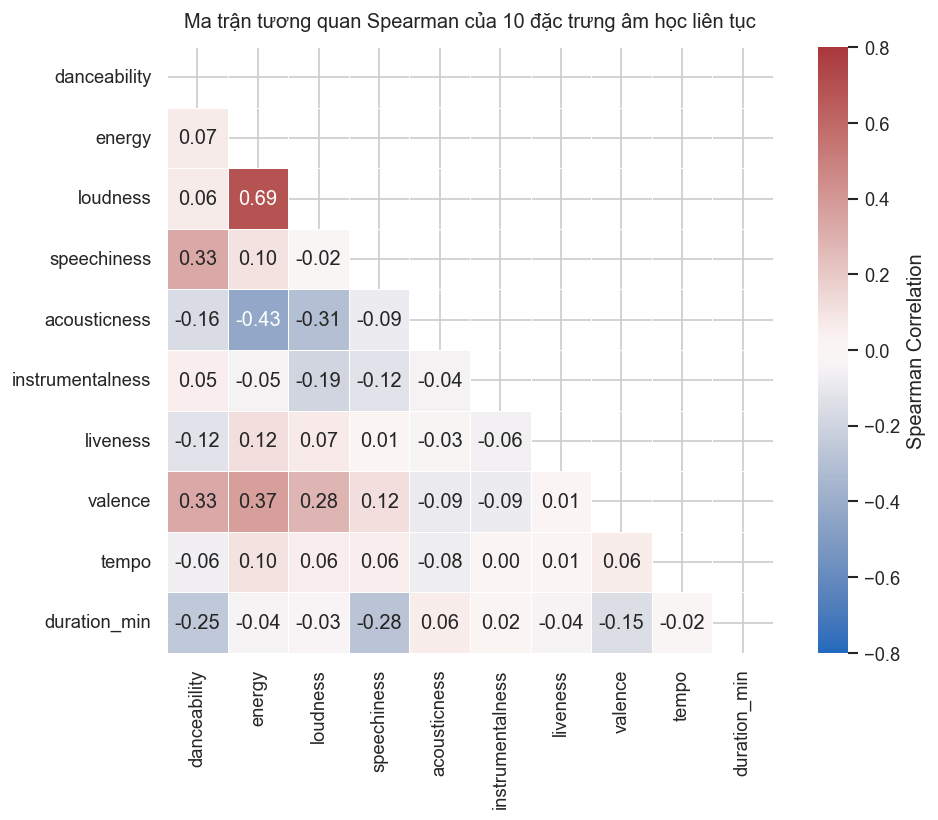

In [7]:
# Tạo mặt nạ nửa tam giác trên để ẩn phần đối xứng
mask = np.triu(np.ones_like(corr_sp, dtype=bool))

plt.figure(figsize=(9, 7))
sns.heatmap(
    corr_sp, mask=mask, annot=True, fmt='.2f', cmap='vlag',
    vmin=-0.8, vmax=0.8, square=True, linewidths=0.5,
    cbar_kws={'label': 'Spearman Correlation'}
)
plt.title('Ma trận tương quan Spearman của 10 đặc trưng âm học liên tục', fontsize=12, pad=12)
plt.tight_layout()
plt.show()


### Trích xuất các cặp đặc trưng có tương quan mạnh nhất
Đoạn mã lọc danh sách các cặp biến có độ tương quan tuyệt đối lớn nhất để cung cấp số liệu định lượng cho phần đánh giá.


In [8]:
pairs = []
for i in range(len(cols_audio_10)):
    for j in range(i + 1, len(cols_audio_10)):
        c1, c2 = cols_audio_10[i], cols_audio_10[j]
        val = corr_sp.loc[c1, c2]
        pairs.append({'biến_1': c1, 'biến_2': c2, 'spearman_r': val, 'abs_r': abs(val)})

df_top_corr = pd.DataFrame(pairs).sort_values('abs_r', ascending=False).head(5)
print('các cặp biến có tương quan tuyệt đối cao nhất:')
for _, r in df_top_corr.iterrows():
    print(f"  {r['biến_1']} - {r['biến_2']}: r = {r['spearman_r']:+.3f}")


các cặp biến có tương quan tuyệt đối cao nhất:
  energy - loudness: r = +0.690
  energy - acousticness: r = -0.431
  energy - valence: r = +0.369
  danceability - speechiness: r = +0.331
  danceability - valence: r = +0.327


### Nhận xét thực chứng tương quan giữa các đặc trưng
1. Cặp đồng biến mạnh nhất là Energy và Loudness (Spearman r = +0.690): Âm lượng lớn đi kèm mức năng lượng cao.
2. Cặp nghịch biến mạnh nhất là Energy và Acousticness (Spearman r = -0.431): Bản nhạc sử dụng nhiều nhạc cụ mộc tự nhiên thường đối lập với cường độ năng lượng cao của nhạc điện tử.
3. Valence có tương quan dương vừa phải với Energy (r = +0.369) và Danceability (r = +0.327), thể hiện sắc thái vui tươi thường gắn liền với tiết tấu khiêu vũ và năng lượng sôi động.
4. Đánh giá đa cộng tuyến: Mặc dù từng cặp biến chưa vượt ngưỡng 0.70 (+0.690), Energy và Loudness chia sẻ lượng thông tin chồng lấn đáng kể; nguy cơ đa cộng tuyến đối với mô hình hồi quy sẽ được kiểm tra chặt chẽ bằng hệ số phóng đại phương sai (VIF) trên tập huấn luyện Train trong bước mô hình hóa.
5. Lưu ý: Phép phân tích tương quan trên 39,190 ca khúc đóng vai trò mô tả tổng quan; quyết định lựa chọn biến đưa vào mô hình sẽ dựa trên dữ liệu tập Train.


### Chuẩn bị dữ liệu chuỗi thời gian Global
Đoạn mã lọc bảng xu hướng âm thanh tuần của thị trường Global chuẩn giai đoạn 2017 đến 2022 và tính đường trung bình trượt bốn tuần.


In [9]:
# Lọc bảng xu hướng thị trường global chuẩn giai đoạn 2017 đến 2022
df_g_trend = df_mart_audio[df_mart_audio['chart_country'] == 'Global'].copy()
df_g_trend['week'] = pd.to_datetime(df_g_trend['week'])
df_g_trend = df_g_trend[df_g_trend['week'].dt.year.between(2017, 2022)].sort_values('week').reset_index(drop=True)

trend_feats = ['danceability_weighted', 'energy_weighted', 'valence_weighted', 'acousticness_weighted']
# Tính đường trượt 4 tuần cho từng đặc trưng
for c in trend_feats:
    df_g_trend[f'{c}_roll4'] = df_g_trend[c].rolling(window=4, min_periods=1).mean()

print('thông tin chuỗi xu hướng global:')
print(f'  số tuần quan sát: {len(df_g_trend)} tuần ({df_g_trend["week"].min().date()} đến {df_g_trend["week"].max().date()})')


thông tin chuỗi xu hướng global:
  số tuần quan sát: 289 tuần (2017-01-05 đến 2022-07-14)


### Trực quan hóa xu hướng âm thanh dài hạn và tính mùa vụ
Đoạn mã vẽ diễn biến bốn chỉ số âm thanh theo tuần và đánh dấu các giai đoạn tháng 12 để làm nổi bật chu kỳ ngày lễ cuối năm.


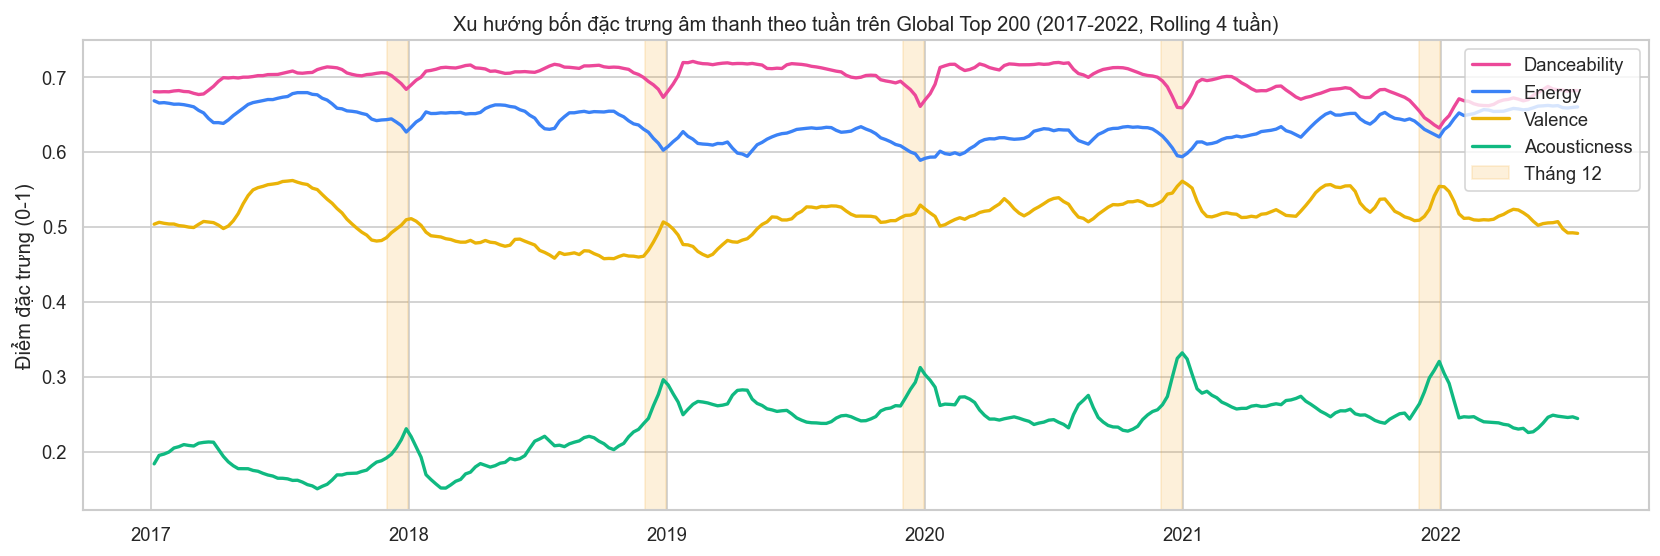

In [10]:
fig, ax = plt.subplots(figsize=(14, 4.8))
palette = {'danceability_weighted': '#EC4899', 'energy_weighted': '#3B82F6', 'valence_weighted': '#EAB308', 'acousticness_weighted': '#10B981'}
names = {'danceability_weighted': 'Danceability', 'energy_weighted': 'Energy', 'valence_weighted': 'Valence', 'acousticness_weighted': 'Acousticness'}

for c in trend_feats:
    ax.plot(df_g_trend['week'], df_g_trend[f'{c}_roll4'], label=names[c], color=palette[c], linewidth=2.0)

for yr in df_g_trend['week'].dt.year.unique():
    d_start, d_end = pd.Timestamp(year=yr, month=12, day=1), pd.Timestamp(year=yr, month=12, day=31)
    if d_start >= df_g_trend['week'].min() and d_start <= df_g_trend['week'].max():
        ax.axvspan(d_start, min(d_end, df_g_trend['week'].max()), color='#F59E0B', alpha=0.15, label='Tháng 12' if yr == 2017 else '')

ax.set_title('Xu hướng bốn đặc trưng âm thanh theo tuần trên Global Top 200 (2017-2022, Rolling 4 tuần)', fontsize=12)
ax.set_ylabel('Điểm đặc trưng (0-1)')
ax.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()


### Thống kê trung bình theo từng năm và chu kỳ tháng 12
Đoạn mã tính giá trị trung bình từ chuỗi số liệu gốc theo từng năm quan sát và đối chiếu sự khác biệt giữa tháng 12 với các tháng khác.


In [11]:
df_g_trend['year'] = df_g_trend['week'].dt.year
df_g_trend['tháng_12'] = np.where(df_g_trend['week'].dt.month == 12, 'Tháng 12', 'Tháng 1-11')

# Bảng thống kê trung bình từng năm từ chuỗi gốc
yearly_stats = df_g_trend.groupby('year').agg(
    số_tuần=('week', 'count'), danceability=('danceability_weighted', 'mean'),
    energy=('energy_weighted', 'mean'), valence=('valence_weighted', 'mean'),
    acousticness=('acousticness_weighted', 'mean')
).round(3)

# Bảng so sánh tháng 12 và các tháng khác
dec_stats = df_g_trend.groupby('tháng_12')[trend_feats].mean().round(3)
dec_stats.columns = ['Danceability', 'Energy', 'Valence', 'Acousticness']

print('thống kê trung bình theo từng năm quan sát (năm 2022 có 28 tuần):')
display(yearly_stats)
print('so sánh trung bình tháng 12 so với các tháng khác:')
display(dec_stats)


thống kê trung bình theo từng năm quan sát (năm 2022 có 28 tuần):


,số_tuần,danceability,energy,valence,acousticness
year,,,,,
2017,52,0.697,0.657,0.520,0.184
2018,52,0.707,0.645,0.475,0.204
2019,52,0.706,0.617,0.503,0.259
2020,53,0.706,0.617,0.526,0.255
2021,52,0.677,0.632,0.528,0.264
2022,28,0.673,0.657,0.509,0.240


so sánh trung bình tháng 12 so với các tháng khác:


,Danceability,Energy,Valence,Acousticness
tháng_12,,,,
Tháng 1-11,0.699,0.638,0.508,0.229
Tháng 12,0.661,0.607,0.532,0.297


### Nhận xét thực chứng xu hướng dài hạn và tính mùa vụ
1. Tính mùa vụ tháng 12 thể hiện rõ nét: Vào tháng 12, Acousticness tăng từ mức trung bình 0.229 lên 0.297 (+29.7%), trong khi Energy giảm từ 0.638 xuống 0.607 và Danceability giảm từ 0.699 xuống 0.661. Diễn biến này phù hợp với giả thuyết các ca khúc mùa lễ hội / nhạc Giáng sinh quay lại bảng xếp hạng vào dịp cuối năm.
2. Tính ổn định dài hạn: Ngoài biến động định kỳ vào tháng 12, các chỉ số Danceability và Energy giữ mức độ ổn định cao qua các năm 2017 đến 2021; mức acousticness có xu hướng nhích nhẹ từ giai đoạn 2019-2021 (~0.26) so với 2017 (~0.18).
3. Giới hạn dữ liệu năm 2022: Tập dữ liệu năm 2022 kết thúc vào ngày 14/07/2022 (chỉ có 28 tuần quan sát) nên chưa bao gồm chu kỳ tháng 12; do đó không đưa năm 2022 vào so sánh mùa vụ lễ hội.


### Chuẩn bị dữ liệu quốc gia cho hai năm 2021 và 2022
Đoạn mã trích xuất dữ liệu từ mart_country_year cho hai năm 2021 và 2022, tính hệ số tương quan Spearman và p-value cho từng năm.


In [12]:
# Lọc dữ liệu hai năm từ mart_country_year
df_sub_2021 = df_mart_whs[df_mart_whs['year'] == 2021].dropna(subset=['happiness_score', 'valence_weighted']).copy()
df_sub_2022 = df_mart_whs[df_mart_whs['year'] == 2022].dropna(subset=['happiness_score', 'valence_weighted']).copy()

# Tính hệ số tương quan spearman thực tế kèm p-value
r_2021, p_2021 = spearmanr(df_sub_2021['happiness_score'], df_sub_2021['valence_weighted'])
r_2022, p_2022 = spearmanr(df_sub_2022['happiness_score'], df_sub_2022['valence_weighted'])
common_c = set(df_sub_2021['chart_country']).intersection(set(df_sub_2022['chart_country']))

print('thông tin tương quan hạnh phúc và valence theo năm:')
print(f'  năm 2021 (N = {len(df_sub_2021)}): spearman r = {r_2021:+.3f}, p-value = {p_2021:.3f}')
print(f'  năm 2022 (N = {len(df_sub_2022)}): spearman r = {r_2022:+.3f}, p-value = {p_2022:.3f}')
print(f'  số quốc gia có mặt ở cả hai năm: {len(common_c)} quốc gia')


thông tin tương quan hạnh phúc và valence theo năm:
  năm 2021 (N = 68): spearman r = +0.000, p-value = 0.999
  năm 2022 (N = 73): spearman r = +0.064, p-value = 0.589
  số quốc gia có mặt ở cả hai năm: 68 quốc gia


### Trực quan hóa tương quan hạnh phúc và valence hai năm
Đoạn mã vẽ hai biểu đồ phân tán cạnh nhau có chung giới hạn trục, phân loại màu theo khu vực World Bank để so sánh trực quan.


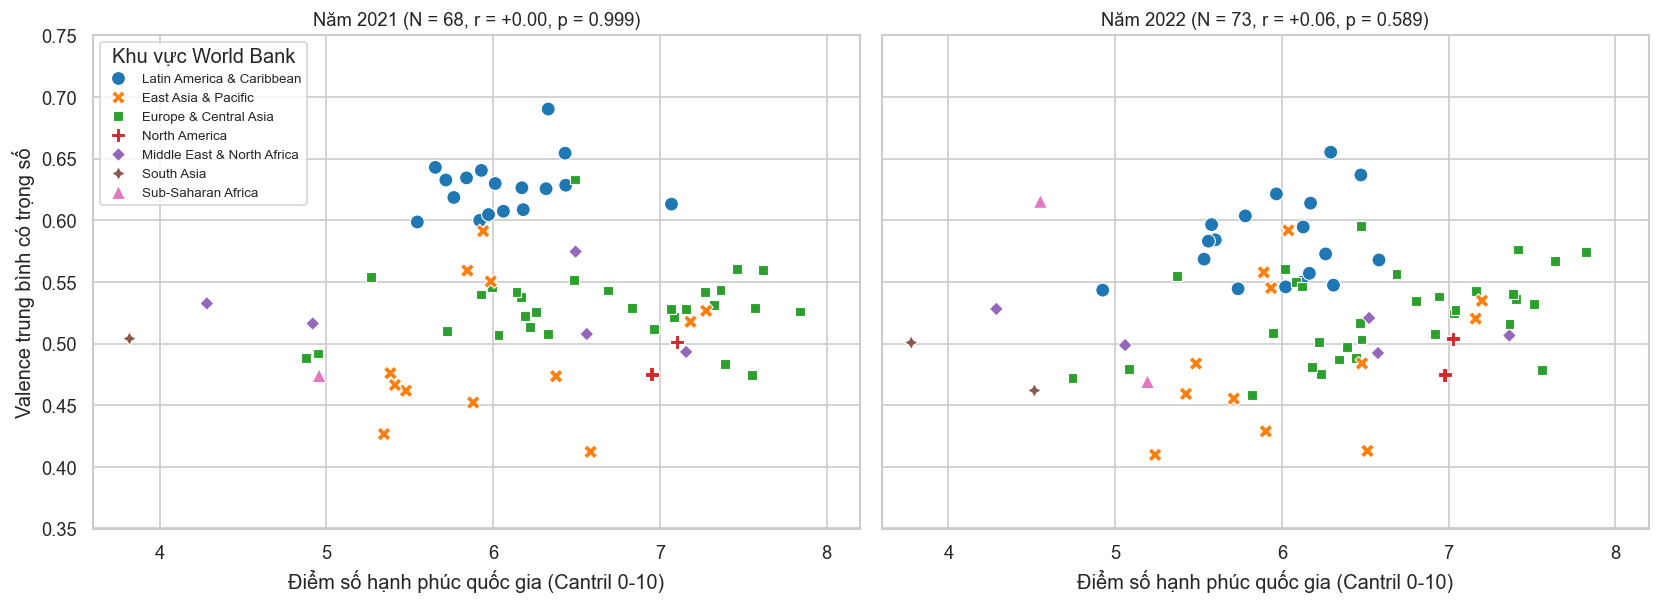

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharex=True, sharey=True)
panels = [(df_sub_2021, 2021, r_2021, p_2021, axes[0]), (df_sub_2022, 2022, r_2022, p_2022, axes[1])]

for df_yr, yr, r_v, p_v, ax in panels:
    sns.scatterplot(
        data=df_yr, x='happiness_score', y='valence_weighted',
        hue='wb_region', style='wb_region', s=70, ax=ax, palette='tab10'
    )
    ax.set_title(f'Năm {yr} (N = {len(df_yr)}, r = {r_v:+.2f}, p = {p_v:.3f})', fontsize=11)
    ax.set_xlabel('Điểm số hạnh phúc quốc gia (Cantril 0-10)')
    ax.set_ylabel('Valence trung bình có trọng số' if yr == 2021 else '')
    ax.set_xlim(3.6, 8.2)
    ax.set_ylim(0.35, 0.75)
    if yr == 2021: ax.legend(title='Khu vực World Bank', fontsize=8, loc='upper left')
    else: ax.get_legend().remove()
plt.tight_layout()
plt.show()


### Nhận xét thực chứng tương quan hạnh phúc và valence
1. Chưa thấy bằng chứng về mối liên hệ đơn điệu rõ ràng: Hệ số Spearman giữa điểm hạnh phúc và valence trên bảng xếp hạng ở cả hai năm đều ở mức rất thấp (năm 2021: r = +0.000, p = 0.999 trên 68 quốc gia; năm 2022: r = +0.064, p = 0.589 trên 73 quốc gia). Với p-value lớn, không đủ cơ sở thống kê để bác bỏ giả thuyết vô hiệu (H0: r = 0).
2. Phân hóa theo văn hóa khu vực: Các quốc gia Mỹ Latinh & Caribe có valence cao nhất (0.60 đến 0.70) dù điểm hạnh phúc ở mức trung bình; ngược lại các quốc gia Bắc Âu có điểm hạnh phúc cao nhất lại có valence thấp hơn (0.45 đến 0.52).
3. Lưu ý phương pháp luận: Số tuần quan sát năm 2022 chưa hoàn toàn đồng đều giữa các thị trường (đa số 28 tuần, nhưng một số thị trường mới có ít tuần hơn như Pakistan 10 tuần, Venezuela 17 tuần). Đồng thời, valence là thước đo đặc tính âm thanh tươi vui trên bảng xếp hạng thương mại, không đại diện cho trạng thái tâm lý hạnh phúc nội tại của người dân.


### Ghép nối dữ liệu âm thanh tuần Global với số ca tử vong COVID
Đoạn mã liên kết chuỗi xu hướng âm thanh tuần Global với dữ liệu dịch tễ tuần từ Johns Hopkins, chỉ giữ các tuần cùng quan sát trong thời kỳ đại dịch.


In [14]:
df_cov_g = df_covid[df_covid['country'] == 'Global'].copy()
df_cov_g['week'] = pd.to_datetime(df_cov_g['week'])

# Ghép nối hai nguồn dữ liệu theo tuần
df_cov_audio = pd.merge(df_g_trend, df_cov_g[['week', 'weekly_deaths']], on='week', how='inner')
# Lọc các tuần có ghi nhận dịch bệnh từ tháng 01/2020
df_cov_active = df_cov_audio[df_cov_audio['week'].ge('2020-01-23') & df_cov_audio['weekly_deaths'].notna()].copy()

print('thông tin chuỗi dữ liệu ghép nối covid và âm thanh:')
print(f'  số tuần cùng quan sát: {len(df_cov_active)} tuần ({df_cov_active["week"].min().date()} đến {df_cov_active["week"].max().date()})')


thông tin chuỗi dữ liệu ghép nối covid và âm thanh:
  số tuần cùng quan sát: 130 tuần (2020-01-23 đến 2022-07-14)


### Trực quan hóa hai tầng đối chiếu tử vong COVID và âm thanh
Đoạn mã biểu diễn đồ thị hai tầng chung trục hoành: tầng trên thể hiện số ca tử vong tuần do đại dịch, tầng dưới thể hiện ba đặc trưng âm thanh đã làm mịn bốn tuần.


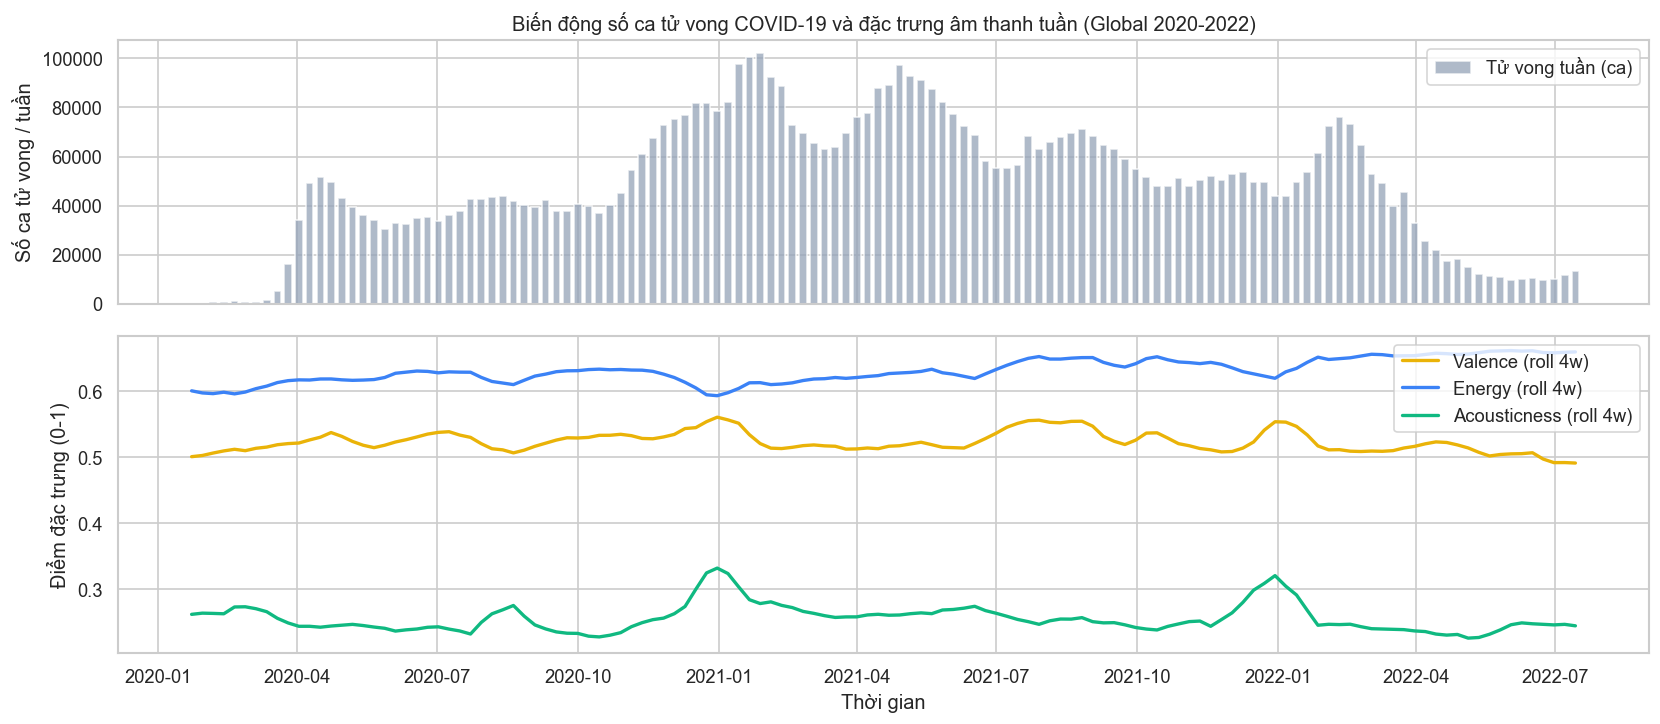

In [15]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 6.2), sharex=True, gridspec_kw={'height_ratios': [1, 1.2]})

# Tầng trên: Số ca tử vong tuần do đại dịch
ax1.bar(df_cov_active['week'], df_cov_active['weekly_deaths'], width=5, color='#94A3B8', alpha=0.75, label='Tử vong tuần (ca)')
ax1.set_ylabel('Số ca tử vong / tuần')
ax1.set_title('Biến động số ca tử vong COVID-19 và đặc trưng âm thanh tuần (Global 2020-2022)', fontsize=12)
ax1.legend(loc='upper right')

# Tầng dưới: Ba đặc trưng âm thanh làm mịn 4 tuần
ax2.plot(df_cov_active['week'], df_cov_active['valence_weighted_roll4'], color='#EAB308', linewidth=2.0, label='Valence (roll 4w)')
ax2.plot(df_cov_active['week'], df_cov_active['energy_weighted_roll4'], color='#3B82F6', linewidth=2.0, label='Energy (roll 4w)')
ax2.plot(df_cov_active['week'], df_cov_active['acousticness_weighted_roll4'], color='#10B981', linewidth=2.0, label='Acousticness (roll 4w)')
ax2.set_ylabel('Điểm đặc trưng (0-1)')
ax2.set_xlabel('Thời gian')
ax2.legend(loc='upper right')
plt.tight_layout()
plt.show()


### Tính tương quan giữa số ca tử vong tuần và đặc trưng âm thanh
Đoạn mã tính hệ số tương quan Spearman giữa số ca tử vong tuần và các chỉ số âm thanh trên cả chuỗi gốc và chuỗi đã làm mịn bốn tuần.


In [16]:
cov_corr_list = []
for f in ['valence_weighted', 'energy_weighted', 'acousticness_weighted']:
    r_raw, p_raw = spearmanr(df_cov_active['weekly_deaths'], df_cov_active[f])
    r_smooth, p_smooth = spearmanr(df_cov_active['weekly_deaths'], df_cov_active[f'{f}_roll4'])
    cov_corr_list.append({
        'đặc_trưng': f,
        'r_chuỗi_gốc': r_raw, 'p_chuỗi_gốc': p_raw,
        'r_làm_mịn_4w': r_smooth, 'p_làm_mịn_4w': p_smooth
    })

df_cov_res = pd.DataFrame(cov_corr_list).round(3)
print('tương quan spearman giữa tử vong tuần và âm thanh trong thời kỳ dịch:')
display(df_cov_res)


tương quan spearman giữa tử vong tuần và âm thanh trong thời kỳ dịch:


,đặc_trưng,r_chuỗi_gốc,p_chuỗi_gốc,r_làm_mịn_4w,p_làm_mịn_4w
0,valence_weighted,0.233,0.008,0.337,0.000
1,energy_weighted,-0.162,0.065,-0.155,0.078
2,acousticness_weighted,0.467,0.000,0.482,0.000


### Nhận xét thực chứng tương quan giữa COVID và hồ sơ âm thanh
1. Kết quả tương quan thực tế: Trên chuỗi số liệu gốc của 130 tuần cùng quan sát (2020-2022), tương quan giữa số ca tử vong tuần và các đặc trưng âm học là: Energy có hệ số âm nhẹ (r = -0.162, p = 0.065), Acousticness đồng biến vừa phải (r = +0.467, p < 0.001), Valence có hệ số dương yếu (r = +0.233, p = 0.008). Trên chuỗi làm mịn 4 tuần, Acousticness đạt r = +0.482 và Valence đạt r = +0.337.
2. Ảnh hưởng của tự tương quan và tính mùa vụ: Tương quan dương đáng kể của Acousticness không phản ánh mối quan hệ nhân quả (người nghe tìm đến âm nhạc mộc để chữa lành tâm lý dịch bệnh), mà chủ yếu xuất phát từ việc các đợt bùng phát tử vong mùa đông cuối năm 2020 trùng khớp với chu kỳ tăng vọt định kỳ của nhạc mùa lễ hội tháng 12.
3. Lưu ý kỹ thuật làm mịn: Phép rolling 4 tuần tạo ra các cửa sổ quan sát chồng lấn làm tăng độ tương quan hình thức nhưng không làm tăng thêm bằng chứng nhân quả.


### Trích xuất cohort tuần đầu và tính nhãn tương lai 8 tuần
Đoạn mã trích xuất lần đầu xuất hiện của từng bài hát trên Global Top 200 và tính toán nhãn nhị phân đạt Global Top 50 trong 8 tuần tiếp theo, đồng bộ hoàn toàn với logic của notebook mô hình.


In [17]:
def extract_cohort(df):
    g = df[df['chart_country'] == 'Global'].drop_duplicates(['track_id', 'week']).sort_values(['week', 'track_id'])
    cal = pd.date_range(g['week'].min(), g['week'].max(), freq='7D')
    top50_v = g.loc[g['rank'].between(1, 50)].groupby('week')['rank'].nunique().reindex(cal, fill_value=0).eq(50)
    first = g.drop_duplicates('track_id', keep='first').copy().reset_index(drop=True)
    first['label_window_end'] = first['week'] + pd.Timedelta(weeks=8)
    rank_map = g.set_index(['track_id', 'week'])['rank']
    full_win, hit = np.ones(len(first), dtype=bool), np.zeros(len(first), dtype=bool)
    for k in range(1, 9):
        fut = first[['track_id', 'week']].copy()
        fut['week'] += pd.Timedelta(weeks=k)
        full_win &= top50_v.reindex(fut['week']).astype('boolean').fillna(False).to_numpy(dtype=bool)
        ranks = rank_map.reindex(pd.MultiIndex.from_frame(fut)).to_numpy()
        hit |= (ranks >= 1) & (ranks <= 50)
    first['hit_next_8_weeks'] = np.where(full_win, hit.astype(int), -1)
    first['eligible'] = full_win & ~first['week'].eq(g['week'].min())
    return first

df_cohort = extract_cohort(df_charts)


### Kiểm tra số lượng mẫu cohort đủ điều kiện
Đoạn mã in thông tin số lượng ca khúc đủ điều kiện gán nhãn dự báo và tỷ lệ nhãn dương sơ bộ của toàn bộ cohort.


In [18]:
n_total = len(df_cohort)
n_eligible = int(df_cohort['eligible'].sum())
pos_eligible = int((df_cohort.loc[df_cohort['eligible'], 'hit_next_8_weeks'] == 1).sum())

print('kết quả trích xuất cohort tuần đầu:')
print(f'  tổng số ca khúc quan sát: {n_total:,} bài')
print(f'  số ca khúc đủ điều kiện nhãn: {n_eligible:,} bài ({n_eligible / n_total:.2%})')
print(f'  số ca khúc đạt top 50 tương lai: {pos_eligible:,} bài ({pos_eligible / n_eligible:.2%})')


kết quả trích xuất cohort tuần đầu:
  tổng số ca khúc quan sát: 5,347 bài
  số ca khúc đủ điều kiện nhãn: 4,665 bài (87.25%)
  số ca khúc đạt top 50 tương lai: 1,067 bài (22.87%)


### Phân chia tập huấn luyện Train theo thời gian
Đoạn mã xác định mốc chia thời gian theo phân vị và lọc lấy tập Train, loại bỏ phần rò rỉ nhãn 8 tuần giáp ranh với tập kiểm định.


In [19]:
# Lấy mốc phân vị 60% làm điểm khởi đầu của validation
el = df_cohort[df_cohort['eligible']]
val_start = el.loc[el['week'].ge(el['week'].quantile(0.60)), 'week'].min()

# Tập train kết thúc trước mốc validation ít nhất 8 tuần để tránh rò rỉ nhãn
df_train = df_cohort[
    df_cohort['eligible'] & 
    df_cohort['week'].lt(val_start) & 
    df_cohort['label_window_end'].lt(val_start)
].copy()

print('thông tin phân vùng tập huấn luyện:')
print(f'  số bài hát trong tập train: {len(df_train):,} bài')
print(f'  giai đoạn tuần đầu: {df_train["week"].min().date()} đến {df_train["week"].max().date()}')


thông tin phân vùng tập huấn luyện:
  số bài hát trong tập train: 2,625 bài
  giai đoạn tuần đầu: 2017-01-05 đến 2020-01-02


### Thống kê phân phối nhãn theo phân tầng thứ hạng tuần đầu
Đoạn mã tính toán tỷ lệ nhãn dương theo bốn phân tầng thứ hạng tuần đầu và so sánh mức độ phân hóa của lượt streams tuần đầu trên tập Train.


In [20]:
# Phân tầng thứ hạng tuần đầu và tổng hợp tỷ lệ nhãn dương
df_train['rank_tier'] = pd.cut(df_train['rank'], bins=[0, 50, 100, 150, 200], labels=['1-50', '51-100', '101-150', '151-200'])
df_tier_stats = df_train.groupby('rank_tier', observed=True).agg(
    tổng_số=('hit_next_8_weeks', 'count'),
    nhãn_dương=('hit_next_8_weeks', lambda s: (s == 1).sum()),
    tỷ_lệ_đạt=('hit_next_8_weeks', lambda s: (s == 1).mean())
).reset_index()
df_tier_stats['tỷ_lệ_đạt'] = (df_tier_stats['tỷ_lệ_đạt'] * 100).round(2).astype(str) + '%'

# Thống kê cho nhóm khởi đầu ngoài Top 50 và trung vị streams
df_train_51 = df_train[df_train['rank'].between(51, 200)]
c_all = df_train['hit_next_8_weeks'].value_counts().sort_index()
c_51 = df_train_51['hit_next_8_weeks'].value_counts().sort_index()
med_s0, med_s1 = df_train.groupby('hit_next_8_weeks')['streams'].median()

print('phân phối nhãn theo phân tầng thứ hạng tuần đầu:')
print(df_tier_stats.to_string(index=False))
print(f'  toàn bộ train: Y=0 có {c_all[0]:,} ({c_all[0]/len(df_train):.2%}), Y=1 có {c_all[1]:,} ({c_all[1]/len(df_train):.2%})')
print(f'  khởi đầu hạng 51-200: Y=0 có {c_51[0]:,} ({c_51[0]/len(df_train_51):.2%}), Y=1 có {c_51[1]:,} ({c_51[1]/len(df_train_51):.2%})')
print(f'  trung vị streams tuần đầu: Y=0 đạt {med_s0:,.0f}, Y=1 đạt {med_s1:,.0f} (gấp {med_s1/med_s0:.1f} lần)')


phân phối nhãn theo phân tầng thứ hạng tuần đầu:
rank_tier  tổng_số  nhãn_dương tỷ_lệ_đạt
     1-50      639         412    64.48%
   51-100      526          90    17.11%
  101-150      602          73    12.13%
  151-200      858          47     5.48%
  toàn bộ train: Y=0 có 2,003 (76.30%), Y=1 có 622 (23.70%)
  khởi đầu hạng 51-200: Y=0 có 1,776 (89.43%), Y=1 có 210 (10.57%)
  trung vị streams tuần đầu: Y=0 đạt 5,258,620, Y=1 đạt 13,082,846 (gấp 2.5 lần)


### Trực quan hóa phân phối nhãn dự báo hai panel
Đoạn mã vẽ hai biểu đồ cột cạnh nhau thể hiện số lượng và tỷ lệ hai lớp nhãn cho toàn bộ tập Train và cho nhóm bắt đầu ở hạng 51-200.


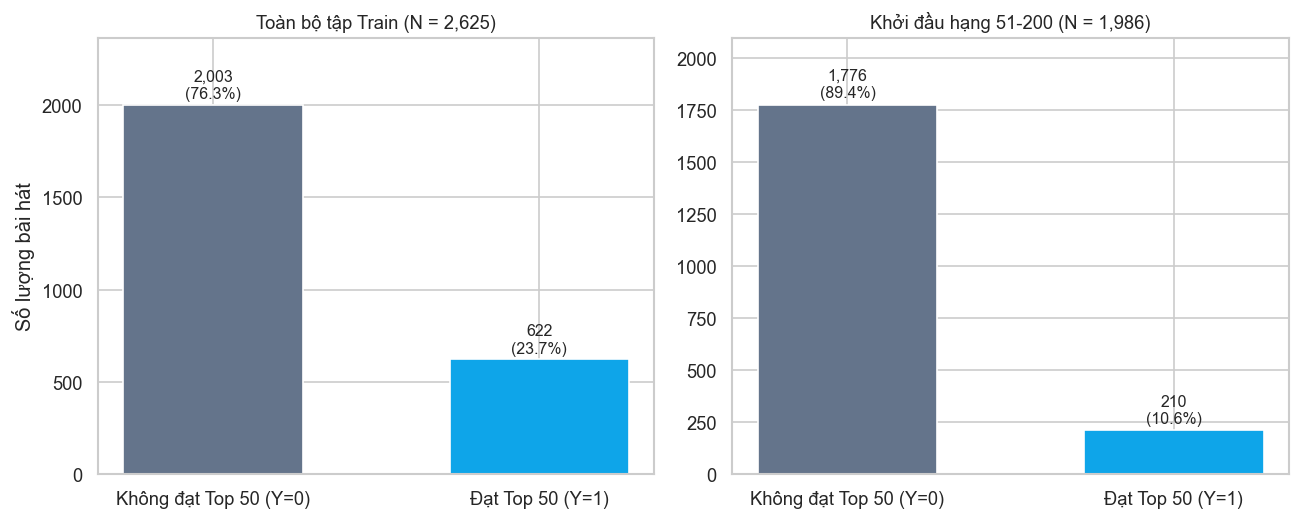

In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
bar_colors = ['#64748B', '#0EA5E9']
labels = ['Không đạt Top 50 (Y=0)', 'Đạt Top 50 (Y=1)']

# Panel 1: Toàn bộ tập Train
b1 = ax1.bar(labels, [c_all[0], c_all[1]], color=bar_colors, width=0.55)
ax1.set_title(f'Toàn bộ tập Train (N = {len(df_train):,})', fontsize=11)
ax1.set_ylabel('Số lượng bài hát')
for b, count, r in zip(b1, [c_all[0], c_all[1]], [c_all[0]/len(df_train), c_all[1]/len(df_train)]):
    ax1.text(b.get_x() + b.get_width()/2, b.get_height() + 35, f'{count:,}\n({r:.1%})', ha='center', fontsize=9.5)
ax1.set_ylim(0, max(c_all) * 1.18)

# Panel 2: Nhóm khởi đầu hạng 51-200
b2 = ax2.bar(labels, [c_51[0], c_51[1]], color=bar_colors, width=0.55)
ax2.set_title(f'Khởi đầu hạng 51-200 (N = {len(df_train_51):,})', fontsize=11)
for b, count, r in zip(b2, [c_51[0], c_51[1]], [c_51[0]/len(df_train_51), c_51[1]/len(df_train_51)]):
    ax2.text(b.get_x() + b.get_width()/2, b.get_height() + 35, f'{count:,}\n({r:.1%})', ha='center', fontsize=9.5)
ax2.set_ylim(0, max(c_51) * 1.18)
plt.tight_layout()
plt.show()


### Nhận xét thực chứng phân phối nhãn và định hướng đánh giá mô hình
1. Phân phối nhãn trên tập Train: Toàn bộ tập Train gồm 2,625 ca khúc, trong đó nhãn dương (đạt Global Top 50 ít nhất một lần trong 8 tuần tiếp theo) chiếm 23.70% (622 bài), nhãn âm chiếm 76.30% (2,003 bài).
2. Phân hóa rõ rệt giữa hai cơ chế bài toán:
   - Cơ chế duy trì thành tích: Các bài hát ra mắt ngay ở Top 50 có tỷ lệ đạt nhãn dương lên tới 64.48% (412 / 639 bài).
   - Cơ chế bứt phá từ nhóm dưới: Với các bài hát khởi đầu ở hạng 51 đến 200, tỷ lệ bứt phá vào Top 50 giảm mạnh xuống chỉ còn 10.57% (210 / 1,986 bài). Khi chia theo từng phân tầng, tỷ lệ này suy giảm nhanh chóng: 17.11% (hạng 51-100), 12.13% (hạng 101-150) và chỉ còn 5.48% (hạng 151-200).
3. Tín hiệu vượt trội từ các đặc trưng thương mại tuần đầu: Lượt nghe tuần đầu của nhóm đạt nhãn dương có trung vị 13,082,846 streams (log streams ~ 16.39), cao gấp 2.5 lần so với nhóm nhãn âm (5,258,620 streams, log streams ~ 15.48). Điều này giải thích tại sao thứ hạng và lượng streams ban đầu mang tín hiệu phân loại cực mạnh, và mô hình dự báo bắt buộc phải kết hợp cả đặc trưng thương mại lẫn đặc trưng âm thanh.
4. Định hướng đánh giá mô hình: Sự mất cân bằng giữa hai lớp (đặc biệt là tỷ lệ 10.57% ở nhóm bứt phá) cho thấy độ chính xác (Accuracy) không phản ánh đúng hiệu quả phân loại; mô hình phân loại bắt buộc phải được đánh giá thông qua Precision, Recall, F1-Score, ROC-AUC và PR-AUC (Average Precision).
